<a href="https://colab.research.google.com/github/Nazarick0912/CPC353/blob/main/CPC353_Assignment_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd

df = pd.read_csv(
    "/content/CPC353_G04_Final_Review_Corpus.csv",
    encoding="utf-8-sig",
    keep_default_na=False
)

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Display the corrected columns
print(df.columns.tolist())

# Display first 5 reviews
display(df.head())

print("Total rows:", len(df))


['Review ID', 'Data Origin', 'Product Category', 'Product / Eatery Name', 'Source Platform', 'Source URL', 'Rating (1-5)', 'Review Date', 'Review Text', 'Language Classification', 'Code-Switching Type']


,Review ID,Data Origin,Product Category,Product / Eatery Name,Source Platform,Source URL,Rating (1-5),Review Date,Review Text,Language Classification,Code-Switching Type
0,REV-001,Self-Collected (Real),Ayam Gepuk,"Ayam Gepuk Original Sungai Dua, Penang",Google Reviews,https://maps.app.goo.gl/GXqZMRFTr2C68gCJ8,1,6 months ago,I’m quite disappointed with the food quality. ...,Code-switched,Intra-sentential
1,REV-002,Self-Collected (Real),Ayam Gepuk,"Ayam Gepuk Original Sungai Dua, Penang",Google Reviews,https://maps.app.goo.gl/5sXxLPesLn6jzj7L8,1,1 year ago,srsla kubis korng bg mcmni je???? I pay for 13...,Code-switched,Intra-sentential; Inter-sentential
2,REV-003,Self-Collected (Real),Ayam Gepuk,"Ayam Gepuk Original Sungai Dua, Penang",Google Reviews,https://share.google/W7iraTWGCIcoWDDYv,1,1 year ago,"Hmmmm judging from the picture, you can say it...",English,N/A
3,REV-004,Self-Collected (Real),Ayam Gepuk,"Ayam Gepuk Original Sungai Dua, Penang",Google Reviews,https://share.google/0QgUt75bNX9fwYpEV,1,1 year ago,I tak suka complain about food. But i bought t...,Code-switched,Intra-sentential; Inter-sentential
4,REV-005,Self-Collected (Real),Ayam Gepuk,"Ayam Gepuk Original Sungai Dua, Penang",Google Reviews,https://maps.app.goo.gl/skfuAanD57teeLVF9,2,1 year ago,Foods okay but lousy customer service i feel. ...,Code-switched,Intra-sentential; Inter-sentential


Total rows: 200


In [ ]:
# Check total number of reviews
print("Total rows:", len(df))

# Check missing review texts
print("Missing reviews:",
      df["Review Text"].isna().sum())

# Check duplicate review texts
print("Duplicate reviews:",
      df["Review Text"].dropna().duplicated().sum())

# Check language distribution
print("\nLanguage classification:")
print(df["Language Classification"].value_counts(dropna=False))

Total rows: 200
Missing reviews: 0
Duplicate reviews: 4

Language classification:
Language Classification
English          86
Code-switched    76
Malay            38
Name: count, dtype: int64


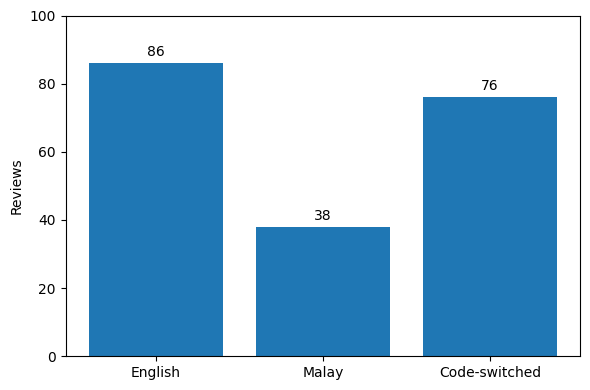

In [ ]:
import matplotlib.pyplot as plt

# Count reviews by language classification
language_counts = df["Language Classification"].value_counts()

# Select the three main categories
categories = ["English", "Malay", "Code-switched"]
counts = [language_counts.get(c, 0) for c in categories]

# Create bar chart
plt.figure(figsize=(6, 4))

bars = plt.bar(categories, counts)

# Add value labels above bars
plt.bar_label(bars, padding=3)

plt.ylabel("Reviews")
plt.ylim(0, 100)

# Save the figure
plt.tight_layout()
plt.savefig(
    "language_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Display duplicate review texts for checking
duplicates = df[
    df.duplicated(subset=["Review Text"], keep=False)
]

display(
    duplicates[
        ["Review ID", "Review Text", "Language Classification"]
    ].sort_values("Review Text")
)

,Review ID,Review Text,Language Classification
145,REV-146,Sedap,Malay
148,REV-149,Sedap,Malay
150,REV-151,Sedap,Malay
175,REV-176,Sedap,Malay
121,REV-122,sedap,Malay
158,REV-159,sedap,Malay


In [ ]:
# Remove duplicate reviews
df_clean = df.drop_duplicates(
    subset=["Review Text"],
    keep="first"
).copy()

# Remove empty or whitespace-only review texts
df_clean = df_clean[
    df_clean["Review Text"].notna()
    & df_clean["Review Text"].astype(str).str.strip().ne("")
].copy()

print("Original reviews:", len(df))
print("Reviews after cleaning:", len(df_clean))
print("Reviews removed:", len(df) - len(df_clean))

Original reviews: 200
Reviews after cleaning: 196
Reviews removed: 4


In [ ]:
# Create a cleaned text column using Python
import re

def clean_text(text):
  if pd.isna(text):
    return ""
  text = str(text).lower()

  # Normalize curly quotes/apostrophes
  text = text.replace("’", "'").replace("‘", "'").replace("`", "'")

  # Normalize repeated characters (sedappppp -> sedap)
  text = re.sub(r"(.)\1{2,}", r"\1\1", text)

  # Keep alphanumeric, spaces, hyphens and apostrophes inside words
  text = re.sub(r"[^\w\s'-]", " ", text)

  # Remove isolated hyphens or apostrophes
  text = re.sub(r"(?<=\s)'|'(?=\s)|(?<=\s)-|-(?=\s)", " ", text)

  # Collapse whitespace
  return re.sub(r"\s+", " ", text).strip()

df_clean["Cleaned_Review"] = (
    df_clean["Review Text"].apply(clean_text)
)

display(
    df_clean[
        ["Review Text", "Cleaned_Review"]
    ].head()
)

,Review Text,Cleaned_Review
0,I’m quite disappointed with the food quality. ...,i'm quite disappointed with the food quality t...
1,srsla kubis korng bg mcmni je???? I pay for 13...,srsla kubis korng bg mcmni je i pay for 13 90 ...
2,"Hmmmm judging from the picture, you can say it...",hmm judging from the picture you can say it's ...
3,I tak suka complain about food. But i bought t...,i tak suka complain about food but i bought th...
4,Foods okay but lousy customer service i feel. ...,foods okay but lousy customer service i feel f...


In [ ]:
# Run N-gram Analysis
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

# Select code-switched reviews
mixed_df = df_clean[
    df_clean["Language Classification"]
    .astype(str).str.strip().str.lower()
    == "code-switched"
].copy()

# Prepare review texts
texts = mixed_df["Cleaned_Review"]
texts = texts[texts.str.strip() != ""]

# Generate bigrams
vectorizer = CountVectorizer(
    ngram_range=(2, 2),
    token_pattern=r"(?u)\b[a-zA-Z0-9]+(?:['-_][a-zA-Z0-9]+)?\b",
)

if texts.empty:
    print("No code-switched reviews found.")
else:
    matrix = vectorizer.fit_transform(texts)

    counts = matrix.sum(axis=0).A1

    bigram_results = pd.DataFrame({
        "Bigram": vectorizer.get_feature_names_out(),
        "Frequency": counts
    }).sort_values("Frequency", ascending=False)

    display(bigram_results.head(20))

,Bigram,Frequency
147,ayam gepuk,14
1142,makanan sedap,7
1859,tak boleh,6
299,bumbu kacang,5
480,dine in,5
1066,level 1,5
1693,sedap service,4
1132,makan sini,4
1185,memang sedap,4
166,bad service,4


In [ ]:
# Generate trigrams
trigram_vectorizer = CountVectorizer(
    ngram_range=(3, 3),
    token_pattern=r"(?u)\b[a-zA-Z0-9]+(?:['-_][a-zA-Z0-9]+)?\b"
)

trigram_matrix = trigram_vectorizer.fit_transform(texts)

trigram_results = pd.DataFrame({
    "Trigram": trigram_vectorizer.get_feature_names_out(),
    "Frequency": trigram_matrix.sum(axis=0).A1
}).sort_values("Frequency", ascending=False)

display(trigram_results.head(20))

,Trigram,Frequency
2008,tapi sambal takda,2
319,bumbu kacang but,2
1910,sorry to say,2
1680,sambal level 1,2
2083,the service is,2
960,kedai ayam gepuk,2
1199,makanan memang sedap,2
2060,the ayam gepuk,2
1981,tak puas hati,2
2298,yang letak dalam,2


In [ ]:
# Concordance analysis for selected words
keywords = ["sedap", "sambal", "spicy", "portion"]

for keyword in keywords:
    print(f"\n--- Concordance for: {keyword} ---")

    matches = mixed_df[
        mixed_df["Cleaned_Review"].str.contains(
            rf"\b{keyword}\b",
            case=False,
            regex=True,
            na=False
        )
    ]

    for review in matches["Review Text"].head(5):
        print("-", review)


--- Concordance for: sedap ---
- Last place on earth to dine in.. makanan tak sedap..
- sedap and good atmospehere.
- Service was good, makanan always sedap✨
- Sedap ! Always my favourite. Tolong la adjust business hour tu buka sampai 6.30pm, sempat la nak p early dinner lepas balik kerja, sebab selalu sangkut jem, elok sampai kedai dah tutup
- Ayam Gempuk for life here hehe. Biasanya saya jarang makan di tempat yang sama lebih daripada sekali, tapi Ayam Gempuk Original Penang nie memang lain macam. Kalau saya repeat makan, itu tandanya memang terbaik untuk selera saya. Taktau berapa kali dah repeat 😭 Ayam dia sangat juicy, rempah rasa sedap dan sambal pula cukup kick 🔥🥵. Service pun tip top, cepat dan efisien. Siap boleh tambah nasi putih dan sambal secara percuma—mana nak dapat kat tempat lain macam ni? Cuma, space agak limited sikit, sebab tempat ni selalu ramai orang. Jadi kena datang waktu bukan peak kalau tak nak tunggu lama 😂. Setiap kali datang sini, tak pernah kecewa. Highly 

In [ ]:
import re

keywords = ["sedap", "sambal", "spicy", "portion"]
concordance_rows = []

for _, row in mixed_df.iterrows():
    review = str(row["Review Text"])

    for keyword in keywords:
        pattern = rf"\b{re.escape(keyword)}\b"

        for match in re.finditer(
            pattern, review, flags=re.IGNORECASE
        ):
            before = review[:match.start()].split()[-5:]
            after = review[match.end():].split()[:5]

            concordance_rows.append({
                "Review ID": row["Review ID"],
                "Before": " ".join(before),
                "Keyword": match.group(),
                "After": " ".join(after)
            })

concordance_df = pd.DataFrame(concordance_rows)

display(concordance_df.head(30))

,Review ID,Before,Keyword,After
0,REV-031,to dine in.. makanan tak,sedap,..
1,REV-032,,sedap,and good atmospehere.
2,REV-033,"Service was good, makanan always",sedap,✨
3,REV-034,,Sedap,! Always my favourite. Tolong
4,REV-035,"dia sangat juicy, rempah rasa",sedap,dan sambal pula cukup kick
5,REV-035,"juicy, rempah rasa sedap dan",sambal,pula cukup kick 🔥🥵. Service
6,REV-035,boleh tambah nasi putih dan,sambal,secara percuma—mana nak dapat kat
7,REV-037,segi layanan pelanggan. Makanan masih,sedap,", cuma service kali ni"
8,REV-038,thru shopeefood. First time makan,sedap,". Suka sambal dia sedap,"
9,REV-038,makan sedap. Suka sambal dia,sedap,", pedas (level 3), sambal"


Visualization

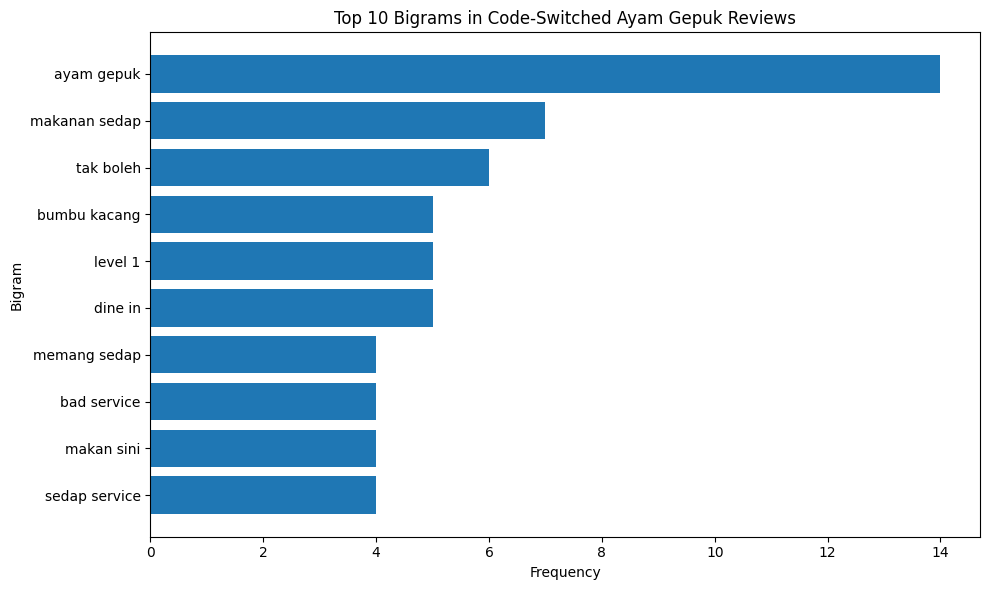

In [ ]:
import matplotlib.pyplot as plt

top_bigrams = bigram_results.head(10).sort_values("Frequency")

plt.figure(figsize=(10, 6))
plt.barh(top_bigrams["Bigram"], top_bigrams["Frequency"])

plt.xlabel("Frequency")
plt.ylabel("Bigram")
plt.title("Top 10 Bigrams in Code-Switched Ayam Gepuk Reviews")

plt.tight_layout()
plt.savefig("bigram_chart.png", dpi=300, bbox_inches="tight")
plt.show()